# 02 — Feature engineering & Elo

Goal: turn raw matches into a **model-ready table** where every feature is something you could have known
*before* the match started. Everything in Phases 3–6 trains on this table, so this is where correctness matters most.

| Feature | Code | What it captures |
|---|---|---|
| Elo, surface Elo | `src/elo.py` | strength learned from who-beat-whom (see [`docs/01_elo.md`](../docs/01_elo.md)) |
| Recent form | `add_recent_form` | win rate over the last 10 matches |
| Head-to-head | `add_head_to_head` | prior wins against this exact opponent |
| Rank, rank points | from the raw data | the official ATP ranking at tournament start |

Then `build_feature_table` combines them and fixes the "winner is always column 1" problem from notebook 01.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_loading import load_matches
from elo import compute_elo_ratings, compute_surface_elo_ratings, elo_win_probability, k_factor
from features import MODEL_INPUTS, NUMERIC_FEATURES, OUTCOME_FLAGS, add_head_to_head, add_recent_form, build_feature_table

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed order: blue, orange, aqua

df = load_matches()
df.shape

(46964, 52)

## 1. Elo

`compute_elo_ratings` walks the matches in order. For each one it **records** both players' current rating
as the pre-match feature, **then** updates them with the result. Read [`docs/01_elo.md`](../docs/01_elo.md) first for the formulas.

In [2]:
elo = compute_elo_ratings(df)          # same row index as df: winner_elo, loser_elo (pre-match)
df_elo = pd.concat([df, elo], axis=1)  # glue the two new columns onto the matches
df_elo[["tourney_date", "tourney_name", "round", "winner_name", "winner_elo", "loser_name", "loser_elo"]].tail()

,tourney_date,tourney_name,round,winner_name,winner_elo,loser_name,loser_elo
46959,2026-05-25,Roland Garros,QF,Jakub Mensik,1949.659545,Joao Fonseca,1972.827553
46960,2026-05-25,Roland Garros,QF,Alexander Zverev,2084.740317,Rafael Jodar,2032.363724
46961,2026-05-25,Roland Garros,SF,Flavio Cobolli,1929.800375,Matteo Arnaldi,1802.350860
46962,2026-05-25,Roland Garros,SF,Alexander Zverev,2092.114130,Jakub Mensik,1968.235602
46963,2026-05-25,Roland Garros,F,Alexander Zverev,2097.815395,Flavio Cobolli,1929.800375


### Spot check: reproduce the worked example from the doc by hand

2024 Australian Open final, Sinner d. Medvedev. If the pre-match ratings + formula give the same post-match ratings
the code stores for each player's *next* match, the update step is right.

In [3]:
final = df_elo[(df_elo.tourney_name == "Australian Open") & (df_elo["round"] == "F")
               & (df_elo.tourney_date.dt.year == 2024)].iloc[0]

def matches_before(player_id, row_label):
    """How many non-walkover matches this player played before this row -> drives K."""
    earlier = df.loc[: row_label - 1]
    return int((((earlier.winner_id == player_id) | (earlier.loser_id == player_id)) & ~earlier.walkover).sum())

expected = elo_win_probability(final.winner_elo, final.loser_elo)
k_w = k_factor(matches_before(final.winner_id, final.name))
k_l = k_factor(matches_before(final.loser_id, final.name))
sinner_after = final.winner_elo + k_w * (1 - expected)
medvedev_after = final.loser_elo - k_l * (1 - expected)
print(f"expected P(Sinner) = {expected:.3f}, K: Sinner {k_w:.1f}, Medvedev {k_l:.1f}")
print(f"by hand:  Sinner {final.winner_elo:.1f} -> {sinner_after:.1f}   Medvedev {final.loser_elo:.1f} -> {medvedev_after:.1f}")

def next_pre_match_elo(player_id, row_label):
    later = df_elo.loc[row_label + 1:]
    nxt = later[(later.winner_id == player_id) | (later.loser_id == player_id)].iloc[0]
    return nxt.winner_elo if nxt.winner_id == player_id else nxt.loser_elo

assert np.isclose(sinner_after, next_pre_match_elo(final.winner_id, final.name))
assert np.isclose(medvedev_after, next_pre_match_elo(final.loser_id, final.name))
print("matches the code ✓")

expected P(Sinner) = 0.623, K: Sinner 26.4, Medvedev 21.2
by hand:  Sinner 2223.2 -> 2233.2   Medvedev 2136.2 -> 2128.2
matches the code ✓


### Rating trajectories

To plot one player over time we need the data in **long format**: one row per *(player, match)* instead of one row
per match. We'll reuse this reshaping idea for recent form below.

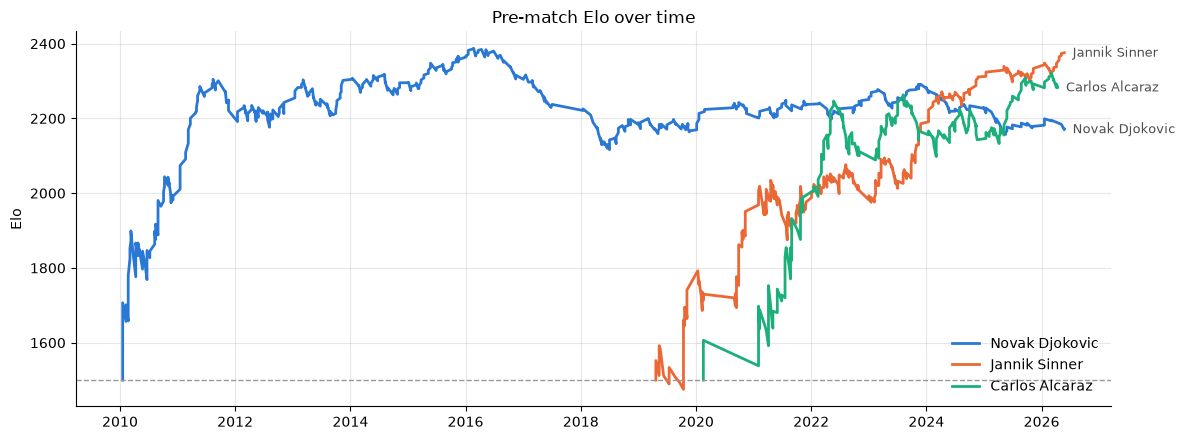

In [4]:
def player_history(frame, value):
    """Long format: one row per (player, match) with that player's pre-match `value` column."""
    w = frame[["tourney_date", "winner_name", f"winner_{value}"]].set_axis(["date", "name", value], axis=1)
    l = frame[["tourney_date", "loser_name", f"loser_{value}"]].set_axis(["date", "name", value], axis=1)
    return pd.concat([w, l]).sort_index(kind="stable")  # index = original match order

hist = player_history(df_elo, "elo")

fig, ax = plt.subplots(figsize=(12, 4.5))
for name, color in zip(["Novak Djokovic", "Jannik Sinner", "Carlos Alcaraz"], COLORS):
    h = hist[hist.name == name]
    ax.plot(h.date, h.elo, color=color, linewidth=2, label=name)
    ax.annotate(name, (h.date.iloc[-1], h.elo.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="0.3", fontsize=9)
ax.axhline(1500, color="0.6", linewidth=1, linestyle="--")
ax.set(title="Pre-match Elo over time", ylabel="Elo")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()

Things to notice:
- **Djokovic starts at 1500 in 2010** even though he was already world #3 — the data only begins in 2010, so Elo
  has to "discover" him. He doesn't reach his true level (~2200+) until mid-2011 — the **cold start** problem.
- Sinner and Alcaraz start at 1500 as unknown teenagers and climb fast: K is huge for their first matches.
- Late in a career, lines get smoother: K shrinks as matches pile up, so single results move the rating less.

## 2. Surface Elo

Same algorithm, but a separate rating per *(player, surface)*. Carpet (66 Davis Cup matches) is counted as Hard —
too few matches for a rating of its own to ever move far from 1500. Here's each player's most recent rating on each surface.

In [5]:
surf = pd.concat([df, compute_surface_elo_ratings(df)], axis=1)

def latest_surface_elo(name):
    rows = {}
    for s in ["Hard", "Clay", "Grass"]:
        m = surf[(surf.surface == s) & ((surf.winner_name == name) | (surf.loser_name == name))].iloc[-1]
        rows[s] = m.winner_surface_elo if m.winner_name == name else m.loser_surface_elo
    return rows

pd.DataFrame({n: latest_surface_elo(n) for n in ["Rafael Nadal", "Novak Djokovic", "Jannik Sinner", "Carlos Alcaraz"]}).round(0)

,Rafael Nadal,Novak Djokovic,Jannik Sinner,Carlos Alcaraz
Hard,2017.0,2175.0,2322.0,2221.0
Clay,2152.0,2093.0,2219.0,2217.0
Grass,1959.0,2182.0,1977.0,2157.0


Nadal's clay rating stands far above his grass rating — exactly the kind of thing overall Elo can't express.
(These are each player's *last* pre-match values, so retired players are frozen at their final match.)

## 3. Recent form

**Form** = share of a player's previous 10 matches that they won. The core line in `add_recent_form` is:

```python
long.groupby("player_id")["won"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
```

- `groupby("player_id")` — do this separately for each player's sequence of matches
- `shift(1)` — move every value down one row, so a match only sees results **before** it. Without this, a match's
  own result would be inside its form — leakage.
- `rolling(10, min_periods=1).mean()` — average over the last (up to) 10 results

### Spot check: recompute one value by hand

In [6]:
form = add_recent_form(df)
row = form.loc[final.name]  # the 2024 AO final again
print(f"code says: Sinner form = {row.winner_form:.2f}, Medvedev form = {row.loser_form:.2f}")

def form_by_hand(player_id, row_label, n=10):
    earlier = df.loc[: row_label - 1]
    earlier = earlier[((earlier.winner_id == player_id) | (earlier.loser_id == player_id)) & ~earlier.walkover]
    last_n = earlier.tail(n)
    return (last_n.winner_id == player_id).mean()

assert np.isclose(row.winner_form, form_by_hand(final.winner_id, final.name))
assert np.isclose(row.loser_form, form_by_hand(final.loser_id, final.name))
print("matches a by-hand count of the previous 10 matches ✓")

code says: Sinner form = 0.90, Medvedev form = 0.80
matches a by-hand count of the previous 10 matches ✓


Form is `NaN` for a player's very first match (no history) and for walkovers (excluded on purpose). About 4% of rows.

## 4. Head-to-head

For each match: how many times had each player beaten this exact opponent **before**? The trick in `add_head_to_head`:
running total (`cumsum`) of wins within each pair, minus this match's own win.

In [7]:
h2h = add_head_to_head(df)
names = {"Jannik Sinner", "Carlos Alcaraz"}
rivalry = h2h[h2h.winner_name.isin(names) & h2h.loser_name.isin(names)]
rivalry[["tourney_date", "tourney_name", "round", "winner_name", "winner_h2h", "loser_h2h"]]

,tourney_date,tourney_name,round,winner_name,winner_h2h,loser_h2h
33451,2021-11-01,Paris Masters,R32,Carlos Alcaraz,0,0
35314,2022-06-27,Wimbledon,R16,Jannik Sinner,0,1
35493,2022-07-25,Umag,F,Jannik Sinner,1,1
35874,2022-08-29,Us Open,QF,Carlos Alcaraz,1,2
37325,2023-03-06,Indian Wells Masters,SF,Carlos Alcaraz,2,2
37420,2023-03-20,Miami Masters,SF,Jannik Sinner,2,3
39098,2023-09-27,Beijing,SF,Jannik Sinner,3,3
40333,2024-03-04,Indian Wells Masters,SF,Carlos Alcaraz,3,4
41040,2024-05-27,Roland Garros,SF,Carlos Alcaraz,4,4
42179,2024-09-26,Beijing,F,Carlos Alcaraz,5,4


Read each row as "**before** this match, the eventual winner had beaten the other player `winner_h2h` times".
The first meeting is 0–0, and each row's counts only reflect rows above it.

Most matches are between players who've never met (stored as 0–0), so H2H only gives an edge in ~38% of matches.

## 5. The feature table

`build_feature_table` puts it all together, and fixes the problem from notebook 01: the raw data is written from the
winner's side, so a model could learn "column 1 always wins". Each match gets a **coin flip** (a hash of its id, so it's the
same every time we rebuild): heads, the winner becomes `player_1`; tails, the loser does. The label `p1_won` is then a fair 50/50.

Every feature is a **difference, `player_1 − player_2`**:

| Column | Positive means |
|---|---|
| `elo_diff`, `surface_elo_diff` | p1 is rated higher |
| `rank_points_diff` | p1 has more ranking points |
| `log_rank_diff` | p1 is ranked **worse** (higher rank number) — rank is "lower is better" |
| `form_diff` | p1 has won more of their last 10 |
| `h2h_diff` | p1 has won more of their previous meetings |

The table also keeps `walkover` and `retired`. Those describe how the match **ended**, so they're for choosing which rows
to train on, never model inputs. `src/features.py` defines `MODEL_INPUTS` (the six diffs + the four context columns) as the
only columns a model may see; Phase 3 uses that list instead of picking columns by hand.

Unranked players get rank 2000 and 0 points (notebook 01, section 4). `log_rank_diff` uses log rank because #1 vs #10
is a much bigger gap than #201 vs #210. Context columns (`surface`, `tourney_level`, `round`, `best_of`) are kept as-is;
Phase 3 one-hot encodes them.

In [8]:
ft = build_feature_table(df)
FEATURES = NUMERIC_FEATURES  # defined once in src/features.py
print(ft.shape)
print(f"p1_won rate: {ft.p1_won.mean():.3f}   (≈0.5 means the coin flip worked)")
assert not set(OUTCOME_FLAGS) & set(MODEL_INPUTS)  # outcome flags are never model inputs
ft.tail()

(46964, 23)
p1_won rate: 0.497   (≈0.5 means the coin flip worked)


,tourney_id,tourney_name,tourney_date,match_num,surface,tourney_level,round,best_of,walkover,retired,p1_id,p2_id,p1_name,p2_name,p1_won,p1_rank,p2_rank,log_rank_diff,rank_points_diff,elo_diff,surface_elo_diff,form_diff,h2h_diff
46959,2026-520,Roland Garros,2026-05-25,222,Clay,G,QF,5,False,False,211663,210150,Joao Fonseca,Jakub Mensik,0,30.0,27.0,0.105361,-115.0,23.168008,2.539971,-0.1,1.0
46960,2026-520,Roland Garros,2026-05-25,223,Clay,G,QF,5,False,False,212588,100644,Rafael Jodar,Alexander Zverev,0,29.0,3.0,2.268684,-4244.0,-52.376593,-38.605455,0.0,0.0
46961,2026-520,Roland Garros,2026-05-25,224,Clay,G,SF,5,True,False,208286,207925,Matteo Arnaldi,Flavio Cobolli,0,104.0,14.0,2.005334,-1754.0,-127.449515,-57.767752,NaN,0.0
46962,2026-520,Roland Garros,2026-05-25,225,Clay,G,SF,5,False,False,100644,210150,Alexander Zverev,Jakub Mensik,1,3.0,27.0,-2.197225,4155.0,123.878528,137.815760,0.1,1.0
46963,2026-520,Roland Garros,2026-05-25,226,Clay,G,F,5,False,False,207925,100644,Flavio Cobolli,Alexander Zverev,0,14.0,3.0,1.540445,-3365.0,-168.015019,-126.789310,-0.1,-2.0


In [9]:
ft[FEATURES].describe().round(2)

,log_rank_diff,rank_points_diff,elo_diff,surface_elo_diff,form_diff,h2h_diff
count,46964.00,46964.00,46964.00,46911.00,45064.00,46964.00
mean,0.01,-4.20,-0.86,-0.22,-0.00,0.01
std,1.50,2475.53,208.99,207.97,0.25,1.41
min,-6.91,-16641.00,-945.32,-926.01,-1.00,-20.00
25%,-0.92,-615.00,-133.09,-131.00,-0.20,0.00
50%,0.01,-1.00,-0.14,0.00,0.00,0.00
75%,0.94,600.00,130.58,129.36,0.20,0.00
max,6.50,16516.00,940.98,921.07,1.00,21.00


## 6. Leakage checks

The single most important test in the project: **does any feature peek into the future?**

Two kinds of leak are possible: from a **later date**, and from a **later round of the same event** (all its matches
share one `tourney_date`). The loader handles the second by sorting by round and asserting it — in ~19 events the raw
`match_num` lists the final first, which would have leaked finals into ~300 earlier rows. The test below covers the first.

If every feature only uses earlier dates, then building the table from data **cut off** at some date must give
*exactly* the same values for the rows before that date as building it from all the data. Any future information
sneaking in would make the two differ.

In [10]:
cutoff = df.tourney_date < "2019-01-01"
partial = build_feature_table(df[cutoff])
pd.testing.assert_frame_equal(ft[cutoff], partial)  # raises an error if a single value differs
print(f"✓ {cutoff.sum():,} rows identical whether or not 2019–2026 data exists")

✓ 26,676 rows identical whether or not 2019–2026 data exists


In [11]:
# Second check: the orientation shouldn't favour either side.
# Among rows where a feature isn't a tie (0) or missing, p1 should be ahead about half the time.
ft[FEATURES].apply(lambda s: (s[s != 0].dropna() > 0).mean()).round(3).to_frame("share where p1 is ahead")

,share where p1 is ahead
log_rank_diff,0.502
rank_points_diff,0.498
elo_diff,0.497
surface_elo_diff,0.500
form_diff,0.498
h2h_diff,0.500


## 7. Does each feature carry signal?

Not modeling yet — just: if you picked the player each feature favours, how often would you be right?
(Walkovers and retirements excluded; ties skipped.)

In [12]:
played = ft[~ft.walkover & ~ft.retired]
signs = {"log_rank_diff": -1}  # for rank, NEGATIVE favours p1

def pick_accuracy(frame, col):
    x = frame[col] * signs.get(col, 1)
    decided = x.notna() & (x != 0)
    return ((x[decided] > 0) == (frame.p1_won[decided] == 1)).mean()

pd.DataFrame({
    "accuracy": {c: pick_accuracy(played, c) for c in FEATURES},
    "rows with a pick": {c: ((played[c].notna()) & (played[c] != 0)).mean() for c in FEATURES},
}).round(3)

,accuracy,rows with a pick
log_rank_diff,0.662,0.997
rank_points_diff,0.662,0.996
elo_diff,0.660,0.995
surface_elo_diff,0.655,0.988
form_diff,0.632,0.811
h2h_diff,0.623,0.379


In [13]:
by_year = pd.DataFrame({
    c: played.groupby(played.tourney_date.dt.year).apply(lambda g: pick_accuracy(g, c))
    for c in ["log_rank_diff", "elo_diff", "surface_elo_diff"]
}).round(3)
by_year.T

tourney_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
log_rank_diff,0.678,0.687,0.688,0.677,0.689,0.693,0.682,0.661,0.644,0.618,0.647,0.640,0.651,0.638,0.641,0.654,0.645
elo_diff,0.650,0.673,0.697,0.672,0.677,0.686,0.686,0.669,0.648,0.639,0.643,0.640,0.654,0.637,0.640,0.647,0.651
surface_elo_diff,0.632,0.661,0.683,0.669,0.677,0.681,0.686,0.667,0.639,0.648,0.658,0.632,0.654,0.630,0.639,0.630,0.652


- Every feature beats a coin flip. Rank and Elo are each ~65–66% alone.
- **Elo doesn't clearly beat the ranking here.** It's weakest in 2010 (cold start — everyone starts at 1500) and catches up
  by ~2012. The dataset also only has tour-level matches, so Elo sees few results for lower-ranked players.
  Phase 3 should consider dropping 2010–2011 from training as **burn-in** (keep them for building ratings, just don't train on them).
- Form and H2H are weaker alone, and H2H only applies to ~40% of matches — but models can combine weak signals.

## 8. Decisions handed to later phases

| Decision | Where | Options |
|---|---|---|
| Train on retirements? | Phase 3 | keep (more data) vs drop (label is partly an injury, not tennis) |
| Burn-in years | Phase 3 | train from 2012 vs 2010 |
| Features for the 2026 test tournament | Phase 6 | ratings **as of each match** (includes earlier rounds of the same event — known before the next round is played) vs **frozen at tournament start** (stricter "predict the whole draw in advance") |

## 9. Check your understanding

1. Why does the Elo loop store the rating *before* updating it? What would go wrong in the other order?
2. Sinner's 2019 rating moved ~240 points in 21 matches; in 2025 it moved ~20 in 64. Why?
3. What does `shift(1)` do in the form calculation, and what happens without it?
4. Why do we flip matches into `player_1`/`player_2` with a hash instead of always putting the winner first?
5. `log_rank_diff` is +1.5 for a match. Who's the better-ranked player?
6. How does the cutoff test prove there's no leakage?
7. Why does Elo start out worse than the ranking in 2010?

<details><summary>1. Store before update</summary>

The stored value is the feature for *this* match, so it must not include this match's result. Updating first would bake
the winner's gain into their own feature — leakage, and the model would look far better than it really is.
</details>

<details><summary>2. Big moves early, small moves late</summary>

K shrinks with matches played (131 at 0 matches, ~19 at 600), and by 2025 he was usually the favourite, so wins were "expected"
and earned little. Both effects shrink the updates.
</details>

<details><summary>3. shift(1)</summary>

It moves each player's results down one row, so the rolling window for a match only covers earlier matches.
Without it, a match's own win/loss is counted in its form: winners would always look in better form — leakage.
</details>

<details><summary>4. The coin flip</summary>

If the winner were always player_1, the label would be "1" every time and a model could learn the column order instead of tennis.
The hash makes the flip random-looking but repeatable, so rebuilding the table gives the same rows.
</details>

<details><summary>5. log_rank_diff = +1.5</summary>

Positive means p1's rank *number* is higher → **player_2** is better ranked. e^1.5 ≈ 4.5, so p1's rank number is ~4.5× p2's (e.g. #45 vs #10).
</details>

<details><summary>6. The cutoff test</summary>

Rows before 2019 get identical features whether or not 2019–2026 exists. If anything looked ahead, adding future
data would change some past value and the comparison would fail.
</details>

<details><summary>7. Elo in 2010</summary>

Our data starts in 2010, so every player — including Djokovic and Nadal — starts at 1500. The ranking already "knows" who's good;
Elo needs a season or more of results to catch up (cold start).
</details>